<a href="https://colab.research.google.com/github/sonhh-3626/data-science-economics/blob/main/visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Bài thực hành: Trực quan hóa dữ liệu với bộ dữ liệu Tips**

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tải dữ liệu
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)
display(df.head())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## **Yêu cầu 1. Trực quan hóa phân phối giá trị hóa đơn**

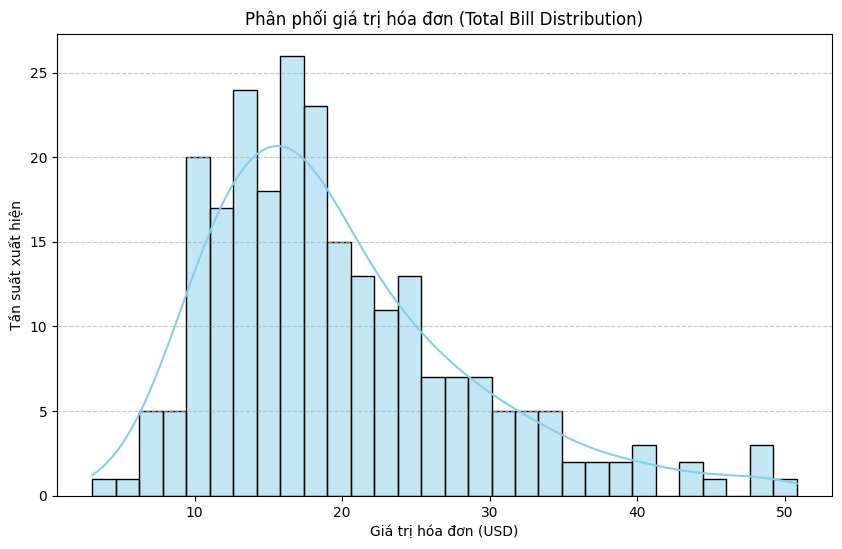

In [12]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='total_bill', kde=True, bins=30, color='skyblue')
plt.title('Phân phối giá trị hóa đơn (Total Bill Distribution)')
plt.xlabel('Giá trị hóa đơn (USD)')
plt.ylabel('Tần suất xuất hiện')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### **Nhận xét & Giải thích (Yêu cầu 1):**
*   **Nhận xét về biểu đồ**:
    *   Giá trị hóa đơn tập trung chủ yếu trong khoảng từ **10 USD đến 25 USD**.
    *   Phân phối dữ liệu **bị lệch phải (skewed right)**, có đuôi kéo dài về phía các giá trị hóa đơn cao.
    *   Có xuất hiện một số hóa đơn có giá trị lớn bất thường dao động từ **40 USD đến hơn 50 USD**.
*   **Giải thích lựa chọn biểu đồ**: Biểu đồ Histogram kết hợp đường KDE (Kernel Density Estimate) là sự lựa chọn tối ưu vì nó cho thấy trực quan tần suất phân bố liên tục của một biến số, giúp nhận diện rõ ràng xu hướng tập trung dữ liệu, độ lệch phân phối cũng như phát hiện các giá trị ngoại lệ cực đoan (outliers).

## **Yêu cầu 2. Mối quan hệ giữa hóa đơn và tiền tip**

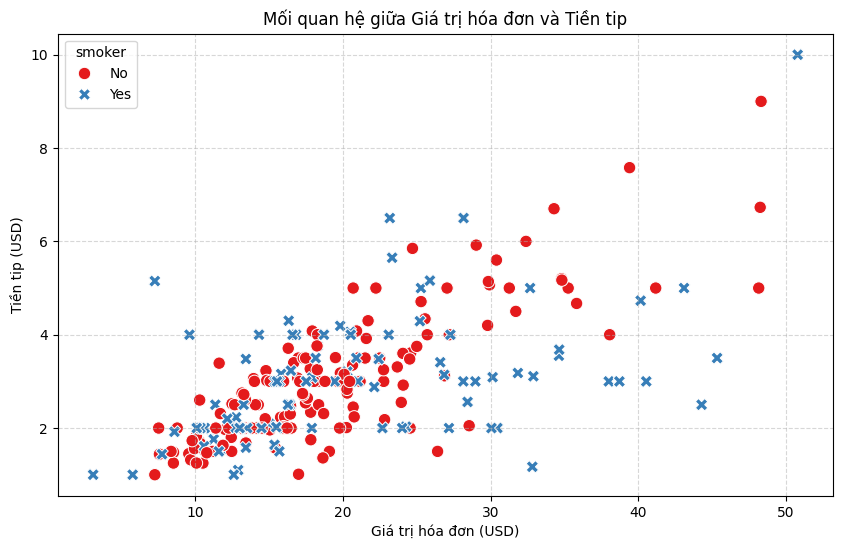

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='total_bill', y='tip', hue='smoker', style='smoker', palette='Set1', s=80)
plt.title('Mối quan hệ giữa Giá trị hóa đơn và Tiền tip')
plt.xlabel('Giá trị hóa đơn (USD)')
plt.ylabel('Tiền tip (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### **Nhận xét (Yêu cầu 2):**
*   Nhìn chung, hóa đơn cao hơn thường đi kèm với tiền tip cao hơn (tương quan thuận tuyến tính tương đối rõ rệt).
*   Hai nhóm khách hút thuốc (Smoker: Yes) và không hút thuốc (Smoker: No) không tạo thành các xu hướng khác nhau quá tách biệt, tuy nhiên nhóm khách hút thuốc có mức độ dao động tiền tip phân tán rộng hơn (nhiều điểm tip cực cao hoặc cực thấp).
*   Có một số điểm dữ liệu ngoại lệ đáng chú ý, ví dụ một hóa đơn chỉ hơn 7 USD nhưng được tip tới hơn 5 USD, hoặc ngược lại một hóa đơn khủng trên 50 USD nhưng chỉ nhận được mức tip khiêm tốn 10 USD.

## **Yêu cầu 3. Ảnh hưởng của số lượng người đến giá trị hóa đơn**

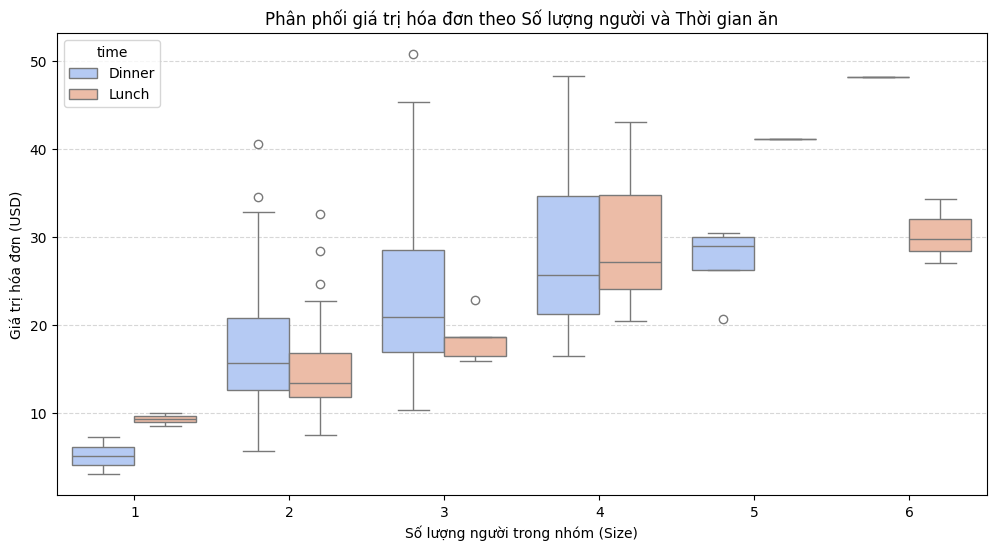

In [14]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='size', y='total_bill', hue='time', palette='coolwarm')
plt.title('Phân phối giá trị hóa đơn theo Số lượng người và Thời gian ăn')
plt.xlabel('Số lượng người trong nhóm (Size)')
plt.ylabel('Giá trị hóa đơn (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### **Nhận xét (Yêu cầu 3):**
*   Số người trong nhóm càng đông thì giá trị hóa đơn trung vị lẫn độ lớn của hộp phân phối càng có xu hướng tăng cao rõ rệt.
*   Mức tăng của hóa đơn không hoàn toàn tỷ lệ thuận tuyến tính 100% với số người (ví dụ nhóm 5 người có hóa đơn phân phối khá tương tự nhóm 4 người và dải biến động rất rộng).
*   Các nhóm có số người lớn (size = 5, 6) có rất ít quan sát (chỉ có 5 và 4 bàn), do đó độ biến động biểu diễn trên Boxplot sẽ không đủ độ tin cậy thống kê cao để đưa ra kết luận chắc chắn so với nhóm phổ biến là size = 2 (156 bàn).